# Apple Stock Price Prediction

This project predicts Apple's next-day closing price from the day's open, high, low, close and volume. It uses the Kaggle "Apple Stock Price History" dataset (11,276 trading days, December 1980 to September 2025) and a Linear Regression model, which is evaluated against a naive baseline.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
df = pd.read_csv("../data/Apple_stock_data.csv")
df = df[["Date","Open", "High", "Low", "Close", "Volume"]]

In [4]:
df.head(3)

,Date,Open,High,Low,Close,Volume
0,1980-12-12,0.098485,0.098913,0.098485,0.098485,469033600
1,1980-12-15,0.093775,0.093775,0.093347,0.093347,175884800
2,1980-12-16,0.086924,0.086924,0.086495,0.086495,105728000


**CHECKING THE DATA**

In [6]:
df.shape

(11276, 6)

In [5]:
df["Date"] = pd.to_datetime(df["Date"])


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11276 entries, 0 to 11275
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    11276 non-null  datetime64[us]
 1   Open    11276 non-null  float64       
 2   High    11276 non-null  float64       
 3   Low     11276 non-null  float64       
 4   Close   11276 non-null  float64       
 5   Volume  11276 non-null  int64         
dtypes: datetime64[us](1), float64(4), int64(1)
memory usage: 528.7 KB


In [8]:
df.isnull().sum()

Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

In [9]:
print("Duplicate dates:",df["Date"].duplicated().sum()) 
df = df.sort_values("Date").reset_index(drop=True)

Duplicate dates: 0


In [35]:
# Days with zero trading volume
print("Days with zero volume:",(df["Volume"]==0).sum())

Days with zero volume: 1


In [11]:
df.describe().round(2)

,Date,Open,High,Low,Close,Volume
count,11276,11276.00,11276.00,11276.00,11276.00,1.127600e+04
mean,2003-04-16 06:22:28.563320,26.32,26.60,26.05,26.34,3.115608e+08
min,1980-12-12 00:00:00,0.04,0.04,0.04,0.04,0.000000e+00
25%,1992-02-05 18:00:00,0.24,0.25,0.24,0.25,1.080611e+08
50%,2003-04-12 12:00:00,0.46,0.47,0.46,0.46,2.002448e+08
75%,2014-06-24 06:00:00,20.68,20.87,20.48,20.64,3.913413e+08
max,2025-09-09 00:00:00,257.28,259.18,256.72,258.10,7.421641e+09
std,NaN,54.52,55.12,53.98,54.58,3.338464e+08


**PLOT PRICE AND VOLUME**

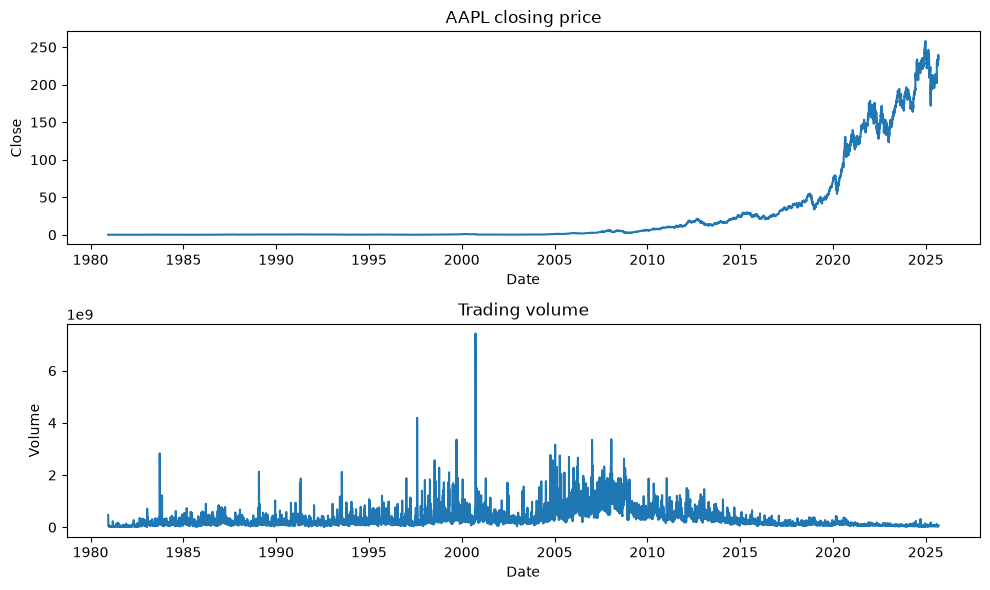

In [12]:
plt.figure(figsize=(10, 6))

plt.subplot(2, 1, 1)
sns.lineplot(data=df, x="Date", y="Close")
plt.title("AAPL closing price")

plt.subplot(2, 1, 2)
sns.lineplot(data=df, x="Date", y="Volume")
plt.title("Trading volume")

plt.tight_layout()
plt.show()


The price stays near zero for years, first passes $1 around

**March 2000**
and $10 around

**January 2011**
, and then climbs steeply to its high of about $258 in

**December 2024**
. Volume was largest around

**September 2000**
and has fallen over time.

"The price level changes by a factor of more than a thousand over the period, so the series is not stable over time."

**CREATING THE TARGET: TOMORROW'S CLOSE**

In [13]:
df["Target"] = df["Close"].shift(-1)    
df = df.dropna()

In [14]:
df.isnull().sum()

Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
Target    0
dtype: int64

In [15]:
x = df.iloc[:, 1:-1]
y = df["Target"]

**SPLITTING DATA TRAIN_TEST_SPLIT**

In [16]:
from sklearn.model_selection import train_test_split

In [17]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42,shuffle=False)

In [18]:
n = len(x_train)
print(x_train.shape, x_test.shape)
print("Train:", df["Date"].iloc[0].date(), "to", df["Date"].iloc[n - 1].date())
print("Test: ", df["Date"].iloc[n].date(), "to", df["Date"].iloc[-1].date())
print("Train price range:", round(y_train.min(), 2), "to", round(y_train.max(), 2))
print("Test price range: ", round(y_test.min(), 2), "to", round(y_test.max(), 2))

(9020, 5) (2255, 5)
Train: 1980-12-12 to 2016-09-16
Test:  2016-09-19 to 2025-09-08
Train price range: 0.04 to 29.65
Test price range:  24.39 to 258.1


**FEATURE SCALING**

In [19]:
from sklearn.preprocessing import StandardScaler

In [21]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print(x_train_scaled.mean(axis=0).round(2))
print(x_train_scaled.std(axis=0).round(2))

[0. 0. 0. 0. 0.]
[1. 1. 1. 1. 1.]


**TRAINING MODEL USING LINEAR REGRESSION**

In [22]:
from sklearn.linear_model import LinearRegression

In [23]:
lr = LinearRegression()
lr.fit(x_train_scaled,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[-0.58, 1.19, 0.67, 5.75, 0. ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.812
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](5,)","[190.01, 94.84, 1.04, 0.81, 0.34]"


**NAIVE BASELINE**

In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [25]:
naive_pred = x_test["Close"]

mae = mean_absolute_error(y_test, naive_pred)
rmse = np.sqrt(mean_squared_error(y_test,naive_pred))
r2 = r2_score(y_test,naive_pred)

print(f"Naive baseline  MAE: {mae:.3f}  RMSE: {rmse:.3f}  R2: {r2:.4f}")
print("Average test price:", round(y_test.mean(), 2))

Naive baseline  MAE: 1.500  RMSE: 2.408  R2: 0.9987
Average test price: 116.45


MAE is the average error in dollars: about 1.50 per day, on an average test price of about 116 (roughly 1.3%). RMSE is similar but punishes large misses more. R² of 0.9987 looks nearly perfect, but remember this is a model that does nothing: it just repeats today's price. R² is so high partly because prices vary enormously across the nine test years.

**EVALUATING WITH THE MODEL PREDICTION**

In [26]:
pred = lr.predict(x_test_scaled)

mae_pred = mean_absolute_error(y_test, pred)
rmse_pred = np.sqrt(mean_squared_error(y_test, pred))
r2_pred = r2_score(y_test,pred)

In [27]:
results = pd.DataFrame({
    "Naive Baseline": [mae,rmse,r2],
    "Linear Regression": [mae_pred,rmse_pred,r2_pred]}, index=["MAE","RMSE","R2"]).round(4)
print(results)


      Naive Baseline  Linear Regression
MAE           1.5003             1.4988
RMSE          2.4078             2.4019
R2            0.9987             0.9987


Linear Regression and the naive baseline are essentially tied: MAE is 1.4988 against 1.5003, and R² is 0.9987 for both. The model gives no meaningful improvement over simply predicting that tomorrow's close equals today's close.

In [33]:
lr.score(x_train_scaled,y_train)*100

99.96459996941849

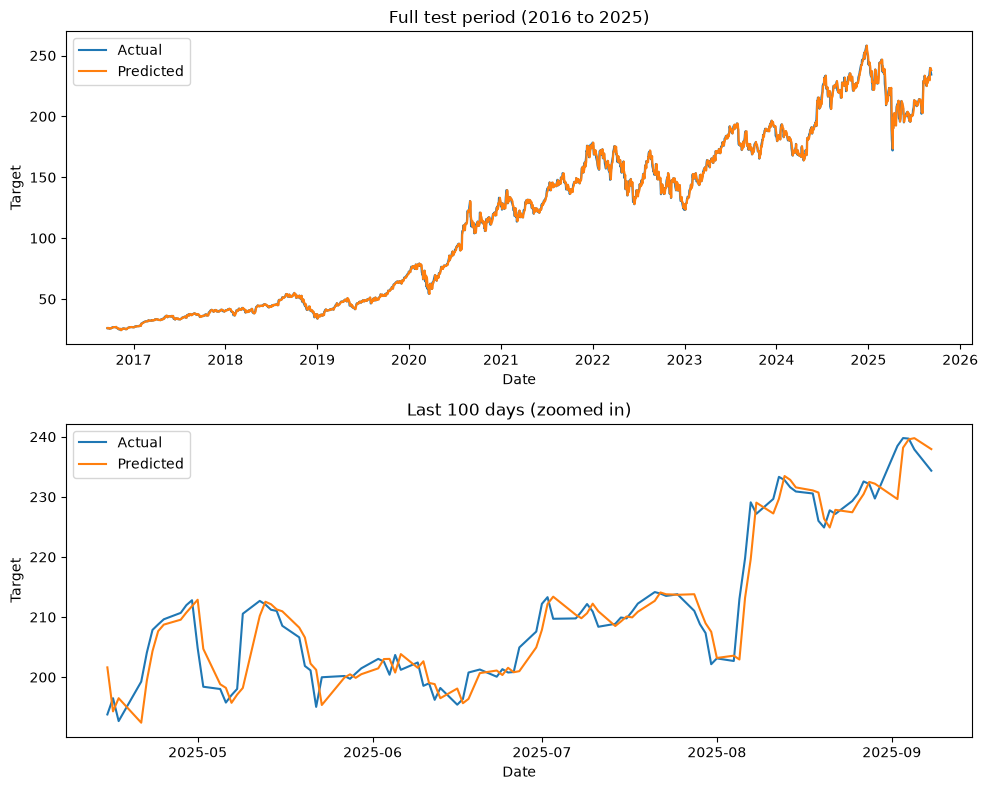

In [29]:
test = df.iloc[len(x_train):]
test["Predicted"] = pred
last = test.tail(100)

plt.figure(figsize=(10, 8))

plt.subplot(2, 1, 1)
sns.lineplot(data=test, x="Date", y="Target", label="Actual")
sns.lineplot(data=test, x="Date", y="Predicted", label="Predicted")
plt.title("Full test period (2016 to 2025)")

plt.subplot(2, 1, 2)
sns.lineplot(data=last, x="Date", y="Target", label="Actual")
sns.lineplot(data=last, x="Date", y="Predicted", label="Predicted")
plt.title("Last 100 days (zoomed in)")

plt.tight_layout()
plt.show()

Over the full test period, the actual and predicted lines overlap almost completely. In the zoomed view of the last 100 days, the predicted line follows the actual one about a day late: it reacts to a price move only after it has happened. This shows that the model mostly repeats the current price, so it follows the trend but cannot anticipate turning points.

# CONCLUSION
I developed a Linear Regression model to predict Apple's next-day closing price using daily opening, high, low, closing prices, and trading volume. The dataset contained 11,276 trading days from December 1980 to September 2025. I used a time-based split, with the first 80% of the data for training and the remaining 20% (September 2016 to September 2025) for testing. The model achieved an MAE of $1.50 and an R² of 0.9987. However, a naive baseline that uses the current day's closing price to predict the next day's close achieved almost identical results, indicating that the model provides little additional predictive value and largely reflects the stock's existing price. Key limitations include the significant difference between training and test-period price levels, reliance solely on historical price and volume data, and the absence of news and market-event information. Future improvements could include adding lagged and moving-average features, predicting daily returns instead of raw prices, and exploring LSTM models.